## 0. Instalacja zależności

In [6]:
!pip install torch torchvision matplotlib

## Import bibliotek

In [7]:
import time, copy, math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

## Konfiguracja eksperymentu (CFG) i wybór urządzenia

In [8]:
CFG = {
    "dataset":    "CIFAR10",
    "epochs":     8,
    "lr":         1e-3,
    "batch_size": 128,
    "n_val":      5000,
    "seed":       42,
    "augment":    False,
    "run_extra":  True,
}

torch.manual_seed(CFG["seed"])
np.random.seed(CFG["seed"])
device = "cuda" if torch.cuda.is_available() else "cpu"

print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)
print("Urządzenie:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)
else:
    print("Wybrałeś CPU")

PyTorch: 2.14.1+cu130 | torchvision: 0.29.1+cu130
Urządzenie: cuda
GPU: Tesla T4
CUDA: 13.0


## 1. Dane i podział 45 000 / 5 000 / 10 000 (trening / walidacja / test)

Zbiór: CIFAR10 | liczba klas: 10
Klasy: ('airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')
Podział: trening 45000 | walidacja 5000 | test 10000
Kształt paczki treningowej: (128, 3, 32, 32) | etykiety: (128,)


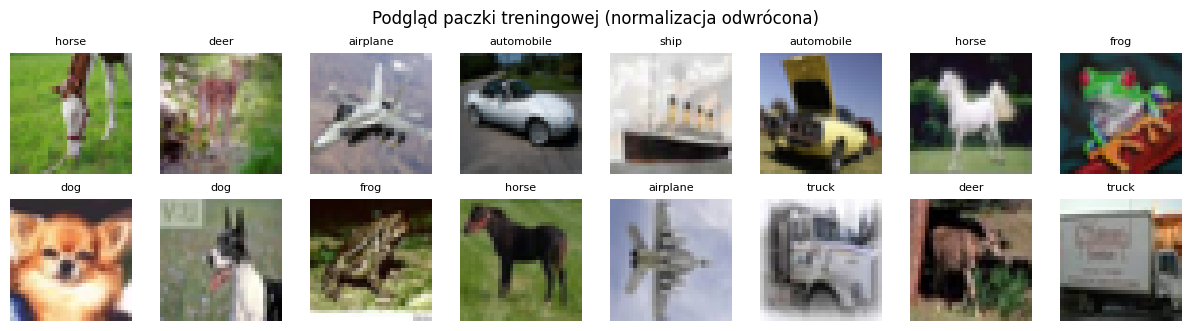

In [9]:
DATASET = CFG["dataset"]

if DATASET == "CIFAR10":
    MEAN, STD  = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
    IN_CH, IMG = 3, (32, 32)
    CLASSES    = ("airplane", "automobile", "bird", "cat", "deer",
                  "dog", "frog", "horse", "ship", "truck")
elif DATASET == "FashionMNIST":
    MEAN, STD  = (0.2860,), (0.3530,)
    IN_CH, IMG = 1, (28, 28)
    CLASSES    = ("T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
                  "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot")
else:
    raise ValueError(f"Nieznany zbiór: {DATASET}")

tf_eval = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
if CFG["augment"]:
    tf_train = transforms.Compose([
        transforms.RandomCrop(IMG[0], padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(), transforms.Normalize(MEAN, STD),
    ])
else:
    tf_train = tf_eval

DS = torchvision.datasets.CIFAR10 if DATASET == "CIFAR10" else torchvision.datasets.FashionMNIST
base_train = DS("./data", train=True,  download=True, transform=tf_train)
base_eval  = DS("./data", train=True,  download=True, transform=tf_eval)
test_ds    = DS("./data", train=False, download=True, transform=tf_eval)

n_train = len(base_train) - CFG["n_val"]
g = torch.Generator().manual_seed(CFG["seed"])
perm = torch.randperm(len(base_train), generator=g).tolist()
val_idx, train_idx = perm[:CFG["n_val"]], perm[CFG["n_val"]:]
train_ds = Subset(base_train, train_idx)
val_ds   = Subset(base_eval,  val_idx)

pin = (device == "cuda")
train_dl = DataLoader(train_ds, batch_size=CFG["batch_size"], shuffle=True,
                      num_workers=2, pin_memory=pin)
val_dl   = DataLoader(val_ds,  batch_size=256, shuffle=False, num_workers=2, pin_memory=pin)
test_dl  = DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=2, pin_memory=pin)

print(f"Zbiór: {DATASET} | liczba klas: {len(CLASSES)}")
print(f"Klasy: {CLASSES}")
print(f"Podział: trening {len(train_ds)} | walidacja {len(val_ds)} | test {len(test_ds)}")
xb, yb = next(iter(train_dl))
print("Kształt paczki treningowej:", tuple(xb.shape), "| etykiety:", tuple(yb.shape))

def denorm(t):
    mean = torch.tensor(MEAN).view(-1, 1, 1)
    std  = torch.tensor(STD).view(-1, 1, 1)
    return (t * std + mean).clamp(0, 1)

imgs = denorm(xb[:16])
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2), constrained_layout=True)
for i, ax in enumerate(axes.flat):
    if IN_CH == 3:
        ax.imshow(np.transpose(imgs[i].numpy(), (1, 2, 0)))
    else:
        ax.imshow(imgs[i, 0].numpy(), cmap="gray")
    ax.set_title(CLASSES[yb[i]], fontsize=8)
    ax.axis("off")
fig.suptitle("Podgląd paczki treningowej (normalizacja odwrócona)")
plt.show()

## 2. Część A - demonstracja poolingu (bez treningu, jeden obraz)

In [10]:
img_t, lab_t = next(iter(val_dl))
image = img_t[:1]
print(f"Obraz wejściowy: {tuple(image.shape)} | klasa: {CLASSES[lab_t[0]]}")

n_in = image[0].numel()
ops = [
    ("nn.MaxPool2d(2)         (max-pooling 2x2)",    nn.MaxPool2d(2)),
    ("nn.AvgPool2d(2)         (average pooling 2x2)", nn.AvgPool2d(2)),
    ("nn.MaxPool2d(4)         (max-pooling 4x4)",    nn.MaxPool2d(4)),
    ("nn.AdaptiveAvgPool2d(1) (GAP)",                nn.AdaptiveAvgPool2d(1)),
]
print(f"\n{'operacja':40} | {'wejście':18} | {'wyjście':14} | redukcja aktywacji")
print("-" * 95)
for name, op in ops:
    out = op(image)
    n_out = out[0].numel()
    print(f"{name:40} | {str(tuple(image.shape)):18} | {str(tuple(out.shape)):14} | "
          f"{n_in}/{n_out} = {n_in // n_out}x mniej")

gap_out = nn.AdaptiveAvgPool2d(1)(image)
print(f"\nGAP: {tuple(image.shape)} -> {tuple(gap_out.shape)}; po spłaszczeniu: {tuple(gap_out.flatten(1).shape)}")

Obraz wejściowy: (1, 3, 32, 32) | klasa: frog

operacja                                 | wejście            | wyjście        | redukcja aktywacji
-----------------------------------------------------------------------------------------------
nn.MaxPool2d(2)         (max-pooling 2x2) | (1, 3, 32, 32)     | (1, 3, 16, 16) | 3072/768 = 4x mniej
nn.AvgPool2d(2)         (average pooling 2x2) | (1, 3, 32, 32)     | (1, 3, 16, 16) | 3072/768 = 4x mniej
nn.MaxPool2d(4)         (max-pooling 4x4) | (1, 3, 32, 32)     | (1, 3, 8, 8)   | 3072/192 = 16x mniej
nn.AdaptiveAvgPool2d(1) (GAP)            | (1, 3, 32, 32)     | (1, 3, 1, 1)   | 3072/3 = 1024x mniej

GAP: (1, 3, 32, 32) -> (1, 3, 1, 1); po spłaszczeniu: (1, 3)


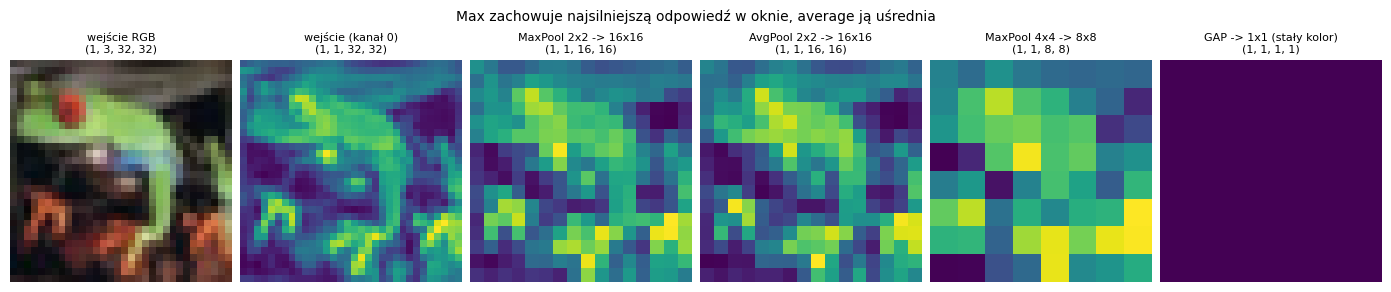

In [23]:
raw = denorm(image)
ch  = raw[:, :1]
mx2 = nn.MaxPool2d(2)(ch); av2 = nn.AvgPool2d(2)(ch); mx4 = nn.MaxPool2d(4)(ch)
gap = nn.AdaptiveAvgPool2d(1)(ch)

import os
os.makedirs("figs", exist_ok=True)

panels = [("wejście (kanał 0)", ch), ("MaxPool 2x2 -> 16x16", mx2),
          ("AvgPool 2x2 -> 16x16", av2), ("MaxPool 4x4 -> 8x8", mx4),
          ("GAP -> 1x1 (stały kolor)", gap)]
if IN_CH == 3:
    panels = [("wejście RGB", raw)] + panels

fig, axes = plt.subplots(1, len(panels), figsize=(2.3 * len(panels), 2.9), constrained_layout=True)
for ax, (name, t) in zip(axes, panels):
    if t.shape[1] == 3:
        ax.imshow(np.transpose(t[0].numpy(), (1, 2, 0)))
    else:
        ax.imshow(t[0, 0].numpy(), cmap="viridis")
    ax.set_title(f"{name}\n{tuple(t.shape)}", fontsize=8)
    ax.axis("off")
fig.suptitle("Max zachowuje najsilniejszą odpowiedź w oknie, average ją uśrednia", fontsize=10)
plt.show()

In [11]:
x = torch.tensor([[ 1.,  2.,  5.,  6.],
                  [ 3.,  4.,  7.,  8.],
                  [ 9.,  1.,  2.,  0.],
                  [ 8.,  6.,  4.,  3.]]).view(1, 1, 4, 4)
print("Mapa wejściowa 4x4:\n", x[0, 0].numpy())

max_manual, avg_manual = torch.zeros(2, 2), torch.zeros(2, 2)
for i in range(2):
    for j in range(2):
        okno = x[0, 0, 2 * i:2 * i + 2, 2 * j:2 * j + 2]
        max_manual[i, j] = okno.max()
        avg_manual[i, j] = okno.mean()
gap_manual = x[0, 0].mean()
print("\nRęcznie - max z okna 2x2:\n", max_manual.numpy())
print("Ręcznie - średnia z okna 2x2:\n", avg_manual.numpy())
print("Ręcznie - średnia z całego kanału (GAP):", float(gap_manual))

max_torch   = F.max_pool2d(x, 2)
avg_torch   = F.avg_pool2d(x, 2)
gap_torch   = F.adaptive_avg_pool2d(x, 1)
print("\nPyTorch - max z okna 2x2:\n", max_torch[0, 0].numpy())
print("PyTorch - średnia z okna 2x2:\n", avg_torch[0, 0].numpy())
print("PyTorch - średnia z całego kanału (GAP):", float(gap_torch[0, 0]))

assert torch.equal(max_manual, max_torch[0, 0])
assert torch.allclose(avg_manual, avg_torch[0, 0])
assert math.isclose(float(gap_manual), float(gap_torch[0, 0]), rel_tol=1e-6)
print("\nWyniki ręczne i PyTorch zgodne - OK")

Mapa wejściowa 4x4:
 [[1. 2. 5. 6.]
 [3. 4. 7. 8.]
 [9. 1. 2. 0.]
 [8. 6. 4. 3.]]

Ręcznie - max z okna 2x2:
 [[4. 8.]
 [9. 4.]]
Ręcznie - średnia z okna 2x2:
 [[2.5  6.5 ]
 [6.   2.25]]
Ręcznie - średnia z całego kanału (GAP): 4.3125

PyTorch - max z okna 2x2:
 [[4. 8.]
 [9. 4.]]
PyTorch - średnia z okna 2x2:
 [[2.5  6.5 ]
 [6.   2.25]]
PyTorch - średnia z całego kanału (GAP): 4.3125

Wyniki ręczne i PyTorch zgodne - OK


## 3. Część B - konfigurowalna klasa CNN

In [24]:
class CNN(nn.Module):
    def __init__(self, in_ch, img_size=(32, 32), pool="max", pool_size=2,
                 head="gap", c1=32, c2=64, c3=128, n_blocks=2, n_classes=10):
        super().__init__()
        def block(cin, cout):
            layers = [nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU()]
            if pool == "max":
                layers.append(nn.MaxPool2d(pool_size))
            elif pool == "avg":
                layers.append(nn.AvgPool2d(pool_size))
            elif pool == "max3":
                layers.append(nn.MaxPool2d(kernel_size=3, stride=2, padding=1))
            elif pool == "stride":
                layers += [nn.Conv2d(cout, cout, 3, stride=pool_size, padding=1),
                           nn.BatchNorm2d(cout), nn.ReLU()]
            elif pool != "none":
                raise ValueError(f"Nieznany wariant poolingu: {pool}")
            return nn.Sequential(*layers)

        if not 1 <= n_blocks <= 3:
            raise ValueError(f"n_blocks: dozwolone 1–3, jest {n_blocks}")
        chans = [in_ch, c1, c2] + ([c3] if n_blocks >= 3 else [])
        self.features = nn.Sequential(*[block(chans[i], chans[i + 1]) for i in range(n_blocks)])
        c_last = chans[n_blocks]

        self.features.eval()
        with torch.no_grad():
            dummy = self.features(torch.zeros(1, in_ch, *img_size))
        self.features.train()
        flat_dim = dummy.shape[1] * dummy.shape[2] * dummy.shape[3]

        if head == "gap":
            self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                      nn.Linear(c_last, n_classes))
        elif head == "flatten":
            self.head = nn.Sequential(nn.Flatten(), nn.Linear(flat_dim, n_classes))
        else:
            raise ValueError(f"Nieznana głowica: {head}")

    def forward(self, x):
        return self.head(self.features(x))

def count_params(model):
    return sum(p.numel() for p in model.parameters())

def param_breakdown(model):
    conv = sum(p.numel() for p in model.features.parameters())
    hd   = sum(p.numel() for p in model.head.parameters())
    return conv, hd

def feature_shape(model):
    model.eval()
    dev = next(model.parameters()).device
    with torch.no_grad():
        return tuple(model.features(torch.zeros(1, IN_CH, *IMG, device=dev)).shape[1:])

print("Głowica GAP, wszystkie warianty redukcji:")
print(f"{'wariant':10} | {'splot':>8} | {'głowica':>8} | {'razem':>8} | {'mapa cech':14} | wyjście")
print("-" * 76)
for pool in ["max", "avg", "max3", "none", "stride"]:
    m = CNN(IN_CH, IMG, pool=pool, head="gap")
    conv_p, head_p = param_breakdown(m)
    out = m(torch.zeros(2, IN_CH, *IMG))
    print(f"{pool:10} | {conv_p:>8,} | {head_p:>8,} | {count_params(m):>8,} | "
          f"{str(feature_shape(m)):14} | {tuple(out.shape)}")

print("\nWpływ liczby bloków (redukcja max, głowica GAP) - końcowy rozmiar mapy cech:")
for nb_ in [1, 2, 3]:
    m = CNN(IN_CH, IMG, pool="max", head="gap", n_blocks=nb_)
    conv_p, head_p = param_breakdown(m)
    print(f"bloków={nb_} | mapa cech {str(feature_shape(m)):14} | parametry (razem) {count_params(m):>8,}")

print("\nPorównanie głowic dla tego samego korpusu splotowego (max):")
for head in ["gap", "flatten"]:
    m = CNN(IN_CH, IMG, pool="max", head=head)
    conv_p, head_p = param_breakdown(m)
    print(f"head={head:8} | splot {conv_p:>8,} | głowica {head_p:>8,} | razem {count_params(m):>8,}")

Głowica GAP, wszystkie warianty redukcji:
wariant    |    splot |  głowica |    razem | mapa cech      | wyjście
----------------------------------------------------------------------------
max        |   19,584 |      650 |   20,234 | (64, 8, 8)     | (2, 10)
avg        |   19,584 |      650 |   20,234 | (64, 8, 8)     | (2, 10)
max3       |   19,584 |      650 |   20,234 | (64, 8, 8)     | (2, 10)
none       |   19,584 |      650 |   20,234 | (64, 32, 32)   | (2, 10)
stride     |   65,952 |      650 |   66,602 | (64, 8, 8)     | (2, 10)

Wpływ liczby bloków (redukcja max, głowica GAP) — końcowy rozmiar mapy cech:
bloków=1 | mapa cech (32, 16, 16)   | parametry (razem)    1,290
bloków=2 | mapa cech (64, 8, 8)     | parametry (razem)   20,234
bloków=3 | mapa cech (128, 4, 4)    | parametry (razem)   94,986

Porównanie głowic dla tego samego korpusu splotowego (max):
head=gap      | splot   19,584 | głowica      650 | razem   20,234
head=flatten  | splot   19,584 | głowica   40,970 | ra

## 4. Testy kontrolne PRZED treningiem

In [13]:
def shape_trace(model, x):
    trace = []
    out = x
    for i, blk in enumerate(model.features):
        out = blk(out)
        trace.append((f"po bloku {i + 1}", tuple(out.shape)))
    out = model.head(out)
    trace.append(("po głowicy", tuple(out.shape)))
    return trace

x_probe = torch.zeros(4, IN_CH, *IMG)
models = {p: CNN(IN_CH, IMG, pool=p, head="gap") for p in ["max", "avg", "none", "stride"]}

for p, m in models.items():
    m.eval()
    logits = m(x_probe)
    assert logits.shape == (4, 10), f"Zły kształt logitów dla pool={p}: {tuple(logits.shape)}"
    print(f"--- pool = {p} (głowica GAP) ---")
    for name, shp in shape_trace(m, x_probe):
        print(f"   {name:12} -> {shp}")
    print(f"   logity: {tuple(logits.shape)} - zgodne z oczekiwanym (4, 10) - OK")

print("\nMapy cech przed głowicą:", {p: feature_shape(m) for p, m in models.items()})

--- pool = max (głowica GAP) ---
   po bloku 1   -> (4, 32, 16, 16)
   po bloku 2   -> (4, 64, 8, 8)
   po głowicy   -> (4, 10)
   logity: (4, 10) - zgodne z oczekiwanym (4, 10) - OK
--- pool = avg (głowica GAP) ---
   po bloku 1   -> (4, 32, 16, 16)
   po bloku 2   -> (4, 64, 8, 8)
   po głowicy   -> (4, 10)
   logity: (4, 10) - zgodne z oczekiwanym (4, 10) - OK
--- pool = none (głowica GAP) ---
   po bloku 1   -> (4, 32, 32, 32)
   po bloku 2   -> (4, 64, 32, 32)
   po głowicy   -> (4, 10)
   logity: (4, 10) - zgodne z oczekiwanym (4, 10) - OK
--- pool = stride (głowica GAP) ---
   po bloku 1   -> (4, 32, 16, 16)
   po bloku 2   -> (4, 64, 8, 8)
   po głowicy   -> (4, 10)
   logity: (4, 10) - zgodne z oczekiwanym (4, 10) - OK

Mapy cech przed głowicą: {'max': (64, 8, 8), 'avg': (64, 8, 8), 'none': (64, 32, 32), 'stride': (64, 8, 8)}


In [14]:
ln10 = math.log(10)
print(f"ln(10) = {ln10:.3f}")
xb, yb = next(iter(train_dl))
crit0 = nn.CrossEntropyLoss()

for p, m in models.items():
    m.train()
    with torch.no_grad():
        loss0 = crit0(m(xb), yb)
    print(f"pool={p:6} | strata startowa = {loss0.item():.3f}  (oczekiwane ~2.3)")
    assert abs(loss0.item() - ln10) < 0.35, f"Strata startowa dla pool={p} daleko od ln(10) - sprawdź kod!"
print("Test straty startowej zaliczony dla wszystkich wariantów.")

ln(10) = 2.303
pool=max    | strata startowa = 2.380  (oczekiwane ~2.3)
pool=avg    | strata startowa = 2.329  (oczekiwane ~2.3)
pool=none   | strata startowa = 2.302  (oczekiwane ~2.3)
pool=stride | strata startowa = 2.365  (oczekiwane ~2.3)
Test straty startowej zaliczony dla wszystkich wariantów.


In [15]:
torch.manual_seed(CFG["seed"])
xb32, yb32 = xb[:32].clone(), yb[:32].clone()
steps = 100
print(f"Paczka: {tuple(xb32.shape)} | kroki: {steps} | Adam, lr={CFG['lr']}")
print(f"{'wariant':8} | {'strata start':>12} | {'strata koniec':>13} | acc na paczce")
print("-" * 55)
for p in ["max", "avg", "none", "stride"]:
    torch.manual_seed(CFG["seed"])
    m = CNN(IN_CH, IMG, pool=p, head="gap")
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(m.parameters(), lr=CFG["lr"])
    m.train()
    for k in range(steps):
        opt.zero_grad()
        loss = crit(m(xb32), yb32)
        if k == 0:
            loss_start = loss.item()
        loss.backward()
        opt.step()
    m.eval()
    acc32 = (m(xb32).argmax(1) == yb32).float().mean().item()
    print(f"{p:8} | {loss_start:>12.3f} | {loss.item():>13.4f} | {acc32 * 100:.0f}%")
print("\nJeśli strata nie spada blisko zera i acc nie dąży do 100% - błąd jest w kodzie, nie w hiperparametrach.")

Paczka: (32, 3, 32, 32) | kroki: 100 | Adam, lr=0.001
wariant  | strata start | strata koniec | acc na paczce
-------------------------------------------------------
max      |        2.282 |        0.2578 | 100%
avg      |        2.292 |        0.5625 | 94%
none     |        2.288 |        0.6547 | 94%
stride   |        2.360 |        0.0538 | 100%

Jeśli strata nie spada blisko zera i acc nie dąży do 100% - błąd jest w kodzie, nie w hiperparametrach.


## 5. Trening i ewaluacja


In [16]:
def train_one_epoch(model, dl, opt, crit):
    model.train()
    tot_loss = tot_correct = tot_n = 0
    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        logits = model(xb)
        loss = crit(logits, yb)
        loss.backward()
        opt.step()
        tot_loss += loss.item() * yb.numel()
        tot_correct += (logits.argmax(1) == yb).sum().item()
        tot_n += yb.numel()
    return tot_loss / tot_n, tot_correct / tot_n

@torch.no_grad()
def evaluate(model, dl, crit):
    model.eval()
    tot_loss = tot_correct = tot_n = 0
    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss = crit(logits, yb)
        tot_loss += loss.item() * yb.numel()
        tot_correct += (logits.argmax(1) == yb).sum().item()
        tot_n += yb.numel()
    return tot_loss / tot_n, tot_correct / tot_n

def fit(model, train_dl, val_dl, epochs=CFG["epochs"], lr=CFG["lr"]):
    model = model.to(device)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best = {"epoch": -1, "val_acc": -1.0, "val_loss": None, "state": None}
    t0 = time.time()
    for ep in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_dl, opt, crit)
        va_loss, va_acc = evaluate(model, val_dl, crit)
        hist["train_loss"].append(tr_loss); hist["train_acc"].append(tr_acc)
        hist["val_loss"].append(va_loss);   hist["val_acc"].append(va_acc)
        star = ""
        if va_acc > best["val_acc"]:
            best = {"epoch": ep, "val_acc": va_acc, "val_loss": va_loss,
                    "state": copy.deepcopy(model.state_dict())}
            star = "  <- najlepsza epoka (zapis wag)"
        print(f"epoka {ep:2d}/{epochs} | trening: strata {tr_loss:.4f}, acc {tr_acc * 100:5.2f}% | "
              f"walidacja: strata {va_loss:.4f}, acc {va_acc * 100:5.2f}%{star}")
    train_time = time.time() - t0
    model.load_state_dict(best["state"])
    return {"model": model, "hist": hist,
            "best": {k: best[k] for k in ("epoch", "val_acc", "val_loss")},
            "train_time": train_time}

## 6. Eksperyment A - rodzaj redukcji: max vs avg vs none vs stride

In [17]:
def run_variant(pool, head="gap", c1=32, c2=64, pool_size=2, seed=CFG["seed"], tag=None):
    torch.manual_seed(seed)
    model = CNN(IN_CH, IMG, pool=pool, head=head, c1=c1, c2=c2, pool_size=pool_size)
    res = fit(model, train_dl, val_dl)
    crit = nn.CrossEntropyLoss()
    test_loss, test_acc = evaluate(res["model"], test_dl, crit)
    conv_p, head_p = param_breakdown(model)
    tr_acc_best = res["hist"]["train_acc"][res["best"]["epoch"] - 1]
    return {
        "wariant": tag or f"{pool} ({head})",
        "pool": pool, "head": head,
        "mapa": str(feature_shape(model)),
        "param_conv": conv_p, "param_head": head_p, "param_all": count_params(model),
        "best_epoch": res["best"]["epoch"],
        "acc_train": tr_acc_best,
        "acc_val": res["best"]["val_acc"],
        "gap": tr_acc_best - res["best"]["val_acc"],
        "acc_test": test_acc, "test_loss": test_loss,
        "czas_s": res["train_time"],
        "hist": res["hist"], "model": res["model"],
    }

def print_results_table(rows):
    print("| wariant | mapa cech | parametry (splot/głowica/razem) | naj. epoka | acc tr [%] | acc wal [%] | przerwa [pp] | acc test [%] | czas [s] |")
    print("|---|---|---|---|---|---|---|---|---|")
    for r in rows:
        print(f"| {r['wariant']} | {r['mapa']} | {r['param_conv']:,} / {r['param_head']:,} / {r['param_all']:,} | "
              f"{r['best_epoch']} | {r['acc_train'] * 100:.2f} | {r['acc_val'] * 100:.2f} | "
              f"{r['gap'] * 100:.2f} | {r['acc_test'] * 100:.2f} | {r['czas_s']:.0f} |")

In [18]:
results_A = {}
rows_A = []
for pool in ["max", "avg", "none", "stride"]:
    print(f"\n=== Eksperyment A: redukcja = {pool}, głowica = GAP ===")
    row = run_variant(pool, head="gap", tag=f"{pool} (GAP)")
    rows_A.append(row)
    results_A[pool] = row

print("\n--- TABELA: Eksperyment A (accuracy w najlepszej epoce walidacyjnej; test oceniany raz) ---")
print_results_table(rows_A)


=== Eksperyment A: redukcja = max, głowica = GAP ===
epoka  1/8 | trening: strata 1.7123, acc 39.83% | walidacja: strata 1.6234, acc 43.52%  <- najlepsza epoka (zapis wag)
epoka  2/8 | trening: strata 1.4870, acc 47.56% | walidacja: strata 1.5027, acc 47.18%  <- najlepsza epoka (zapis wag)
epoka  3/8 | trening: strata 1.4046, acc 50.50% | walidacja: strata 1.4468, acc 47.66%  <- najlepsza epoka (zapis wag)
epoka  4/8 | trening: strata 1.3522, acc 52.54% | walidacja: strata 1.3871, acc 52.00%  <- najlepsza epoka (zapis wag)
epoka  5/8 | trening: strata 1.3121, acc 54.21% | walidacja: strata 1.3887, acc 50.04%
epoka  6/8 | trening: strata 1.2771, acc 55.30% | walidacja: strata 1.3845, acc 51.06%
epoka  7/8 | trening: strata 1.2492, acc 56.29% | walidacja: strata 1.2652, acc 55.04%  <- najlepsza epoka (zapis wag)
epoka  8/8 | trening: strata 1.2249, acc 57.05% | walidacja: strata 1.2917, acc 54.68%

=== Eksperyment A: redukcja = avg, głowica = GAP ===
epoka  1/8 | trening: strata 1.7834,

## 7. Eksperyment B - głowica: GAP vs Flatten


In [19]:
print("\n=== Eksperyment B: głowica Flatten (redukcja = max) ===")
row_flatten = run_variant("max", head="flatten", tag="max (Flatten)")

print("\n--- TABELA: Eksperyment B (GAP vs Flatten) ---")
print_results_table([results_A["max"], row_flatten])

ratio = row_flatten["param_head"] / results_A["max"]["param_head"]
print(f"\nParametry głowicy: GAP = {results_A['max']['param_head']:,}  vs  "
      f"Flatten = {row_flatten['param_head']:,}  ({ratio:.0f}x więcej)")
print("Interpretacja: Flatten kosztuje c2*H*W*n_klas wag; GAP średnio każdą mapę cech do jednej liczby,")
print("więc liczba cech zależy tylko od liczby kanałów (u nas:", f"{results_A['max']['mapa']}) i głowica")
print("przyjmuje mapy o dowolnych wysokościach i szerokościach, o ile wcześniej warstwy potrafiły je przetworzyć.")


=== Eksperyment B: głowica Flatten (redukcja = max) ===
epoka  1/8 | trening: strata 1.3289, acc 53.29% | walidacja: strata 1.0622, acc 63.02%  <- najlepsza epoka (zapis wag)
epoka  2/8 | trening: strata 0.9839, acc 65.76% | walidacja: strata 0.9258, acc 67.86%  <- najlepsza epoka (zapis wag)
epoka  3/8 | trening: strata 0.8563, acc 70.39% | walidacja: strata 0.9455, acc 67.22%
epoka  4/8 | trening: strata 0.7949, acc 72.46% | walidacja: strata 0.9401, acc 68.78%  <- najlepsza epoka (zapis wag)
epoka  5/8 | trening: strata 0.7370, acc 74.52% | walidacja: strata 0.9221, acc 69.88%  <- najlepsza epoka (zapis wag)
epoka  6/8 | trening: strata 0.6947, acc 76.16% | walidacja: strata 0.8594, acc 71.04%  <- najlepsza epoka (zapis wag)
epoka  7/8 | trening: strata 0.6487, acc 77.64% | walidacja: strata 0.8964, acc 70.36%
epoka  8/8 | trening: strata 0.6160, acc 78.77% | walidacja: strata 0.8975, acc 70.44%

--- TABELA: Eksperyment B (GAP vs Flatten) ---
| wariant | mapa cech | parametry (splo

## 8. Powtarzalność - pętla po ziarnach [0, 1, 2]


In [20]:
order = sorted(rows_A, key=lambda r: r["acc_val"])
worst_pool, best_pool = order[0]["pool"], order[-1]["pool"]
print(f"Najlepszy wariant (walidacja): {best_pool} | najsłabszy: {worst_pool}")

seed_rows = {best_pool: [], worst_pool: []}
for pool in [best_pool, worst_pool]:
    for s in [0, 1, 2]:
        print(f"\n=== ziarno {s} | redukcja = {pool} ===")
        seed_rows[pool].append(run_variant(pool, head="gap", seed=s, tag=f"{pool}, seed={s}"))

print("\n--- TABELA: średnia ± odchylenie standardowe (n = 3 ziarna) ---")
print("| wariant | acc wal (średnia ± std) [%] | acc test (średnia ± std) [%] |")
print("|---|---|---|")
for pool, rr in seed_rows.items():
    va = np.array([r["acc_val"] for r in rr])
    te = np.array([r["acc_test"] for r in rr])
    print(f"| {pool} | {va.mean() * 100:.2f} ± {va.std(ddof=1) * 100:.2f} | "
          f"{te.mean() * 100:.2f} ± {te.std(ddof=1) * 100:.2f} |")

Najlepszy wariant (walidacja): stride | najsłabszy: none

=== ziarno 0 | redukcja = stride ===
epoka  1/8 | trening: strata 1.5532, acc 44.97% | walidacja: strata 1.3022, acc 53.30%  <- najlepsza epoka (zapis wag)
epoka  2/8 | trening: strata 1.1750, acc 58.41% | walidacja: strata 1.1277, acc 60.42%  <- najlepsza epoka (zapis wag)
epoka  3/8 | trening: strata 1.0302, acc 63.82% | walidacja: strata 1.0832, acc 61.18%  <- najlepsza epoka (zapis wag)
epoka  4/8 | trening: strata 0.9428, acc 66.74% | walidacja: strata 1.0494, acc 62.88%  <- najlepsza epoka (zapis wag)
epoka  5/8 | trening: strata 0.8795, acc 69.24% | walidacja: strata 0.9765, acc 65.78%  <- najlepsza epoka (zapis wag)
epoka  6/8 | trening: strata 0.8314, acc 70.94% | walidacja: strata 0.9767, acc 66.88%  <- najlepsza epoka (zapis wag)
epoka  7/8 | trening: strata 0.7938, acc 72.27% | walidacja: strata 0.9224, acc 68.08%  <- najlepsza epoka (zapis wag)
epoka  8/8 | trening: strata 0.7542, acc 73.74% | walidacja: strata 0.95

## 9. Eksperyment C - siła redukcji

In [21]:
if CFG["run_extra"]:
    rows_C = []
    for pool_size in [2, 4]:
        for c1, c2 in [(16, 32), (32, 64), (64, 128)]:
            print(f"\n=== Eksperyment C: pool_size = {pool_size}, filtry = ({c1}, {c2}) ===")
            row = run_variant("max", head="gap", c1=c1, c2=c2, pool_size=pool_size,
                              tag=f"ps={pool_size}, f=({c1},{c2})")
            row["ps"], row["fl"] = pool_size, (c1, c2)
            rows_C.append(row)

    print("\n--- TABELA: Eksperyment C (porównanie NA WALIDACJI, test nietknięty) ---")
    print("| pool_size | filtry | mapa cech | parametry (razem) | acc tr [%] | acc wal [%] | przerwa [pp] |")
    print("|---|---|---|---|---|---|---|")
    for r in rows_C:
        print(f"| {r['ps']} | {r['fl']} | {r['mapa']} | {r['param_all']:,} | {r['acc_train'] * 100:.2f} | "
              f"{r['acc_val'] * 100:.2f} | {r['gap'] * 100:.2f} |")
else:
    print("Eksperyment C pominięty")


=== Eksperyment C: pool_size = 2, filtry = (16, 32) ===
epoka  1/8 | trening: strata 1.8420, acc 34.66% | walidacja: strata 1.6954, acc 37.82%  <- najlepsza epoka (zapis wag)
epoka  2/8 | trening: strata 1.5981, acc 43.30% | walidacja: strata 1.5542, acc 45.10%  <- najlepsza epoka (zapis wag)
epoka  3/8 | trening: strata 1.5085, acc 46.54% | walidacja: strata 1.5324, acc 46.76%  <- najlepsza epoka (zapis wag)
epoka  4/8 | trening: strata 1.4545, acc 48.70% | walidacja: strata 1.4734, acc 47.32%  <- najlepsza epoka (zapis wag)
epoka  5/8 | trening: strata 1.4194, acc 49.80% | walidacja: strata 1.4076, acc 50.48%  <- najlepsza epoka (zapis wag)
epoka  6/8 | trening: strata 1.3853, acc 50.94% | walidacja: strata 1.4449, acc 47.60%
epoka  7/8 | trening: strata 1.3599, acc 52.19% | walidacja: strata 1.3965, acc 50.74%  <- najlepsza epoka (zapis wag)
epoka  8/8 | trening: strata 1.3350, acc 52.94% | walidacja: strata 1.3613, acc 52.24%  <- najlepsza epoka (zapis wag)

=== Eksperyment C: poo

## 10. Wizualizacje

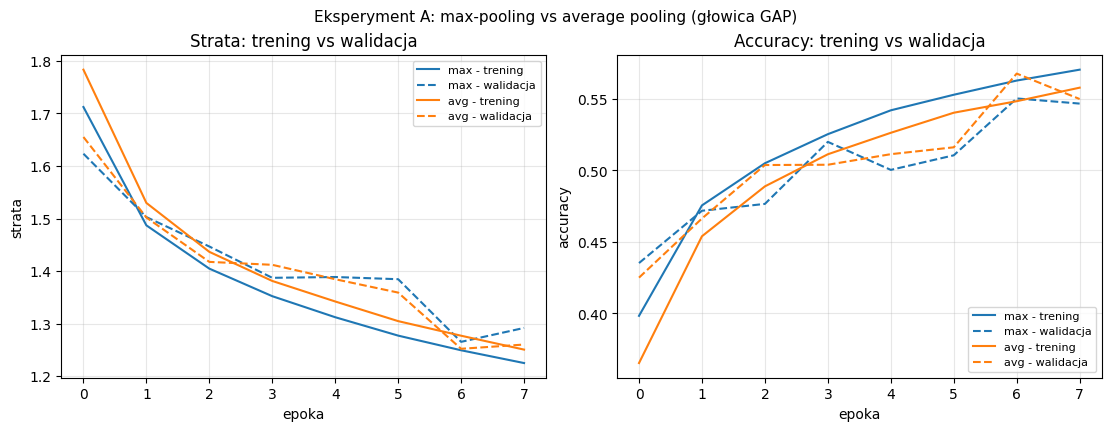

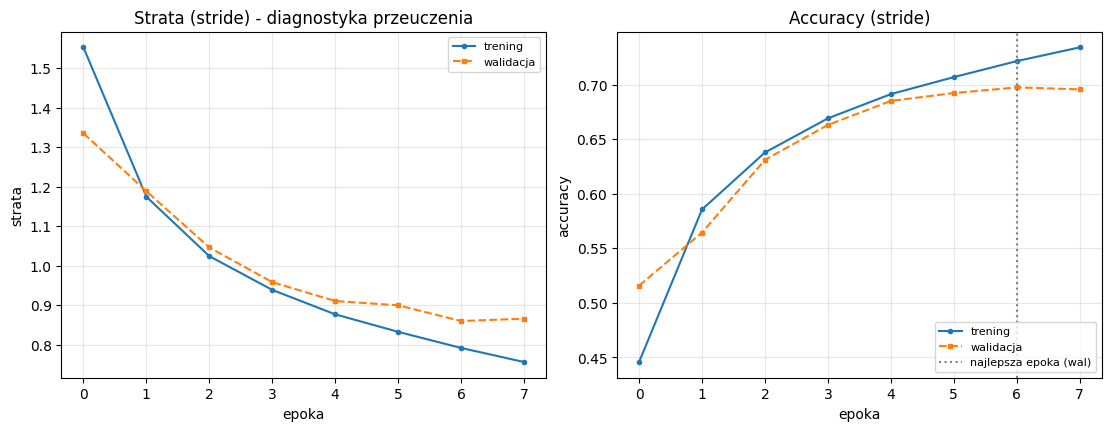

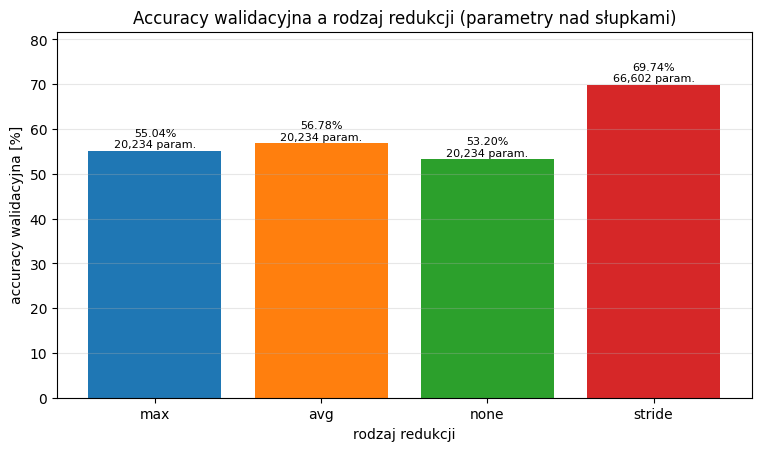

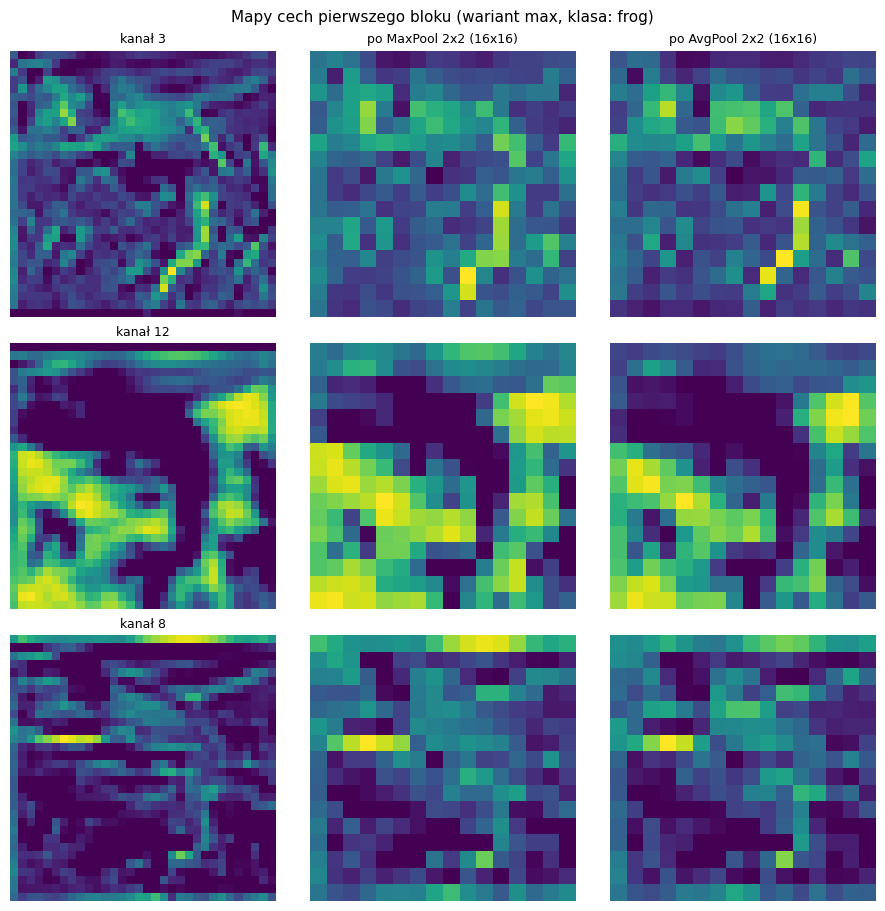

Wykresy zapisane w katalogu figs/: krzywe_max_avg.png, krzywe_najlepszy.png, acc_wal_redukcja.png, mapy_cech_pooling.png


In [22]:
import os
os.makedirs("figs", exist_ok=True)

# 1) Strata i accuracy (trening, walidacja, test) dla max i avg na wspólnych osiachfig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
colors = {"max": "tab:blue", "avg": "tab:orange"}
for pool in ["max", "avg"]:
    h, c = results_A[pool]["hist"], colors[pool]
    axes[0].plot(h["train_loss"], "-", color=c, label=f"{pool} - trening")
    axes[0].plot(h["val_loss"], "--", color=c, label=f"{pool} - walidacja")
    axes[1].plot(h["train_acc"], "-", color=c, label=f"{pool} - trening")
    axes[1].plot(h["val_acc"], "--", color=c, label=f"{pool} - walidacja")
axes[0].set_xlabel("epoka"); axes[0].set_ylabel("strata")
axes[0].set_title("Strata: trening vs walidacja"); axes[0].legend(loc="upper right", fontsize=8)
axes[1].set_xlabel("epoka"); axes[1].set_ylabel("accuracy")
axes[1].set_title("Accuracy: trening vs walidacja"); axes[1].legend(loc="lower right", fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
fig.suptitle("Eksperyment A: max-pooling vs average pooling (głowica GAP)", fontsize=11)
plt.show()

# 1b) Wymóg zadania pkt 4: krzywe ACCURACY (trening i test w funkcji epoki) dla WSZYSTKICH wariantów
fig, ax = plt.subplots(figsize=(8.5, 4.8), constrained_layout=True)
colors_all = {"max": "tab:blue", "avg": "tab:orange", "none": "tab:green", "stride": "tab:red"}
for r in rows_A:
    h, c = r["hist"], colors_all[r["pool"]]
    xs = range(1, len(h["train_acc"]) + 1)
    ax.plot(xs, [a * 100 for a in h["train_acc"]], "-", color=c, label=f"{r['pool']} - trening")
    ax.plot(xs, [a * 100 for a in h["test_acc"]], ":", color=c, label=f"{r['pool']} - test")
ax.set_xlabel("epoka"); ax.set_ylabel("accuracy [%]")
ax.set_title("Krzywe accuracy: trening (linia ciągła) i test (kropkowana) - wszystkie warianty")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
ax.grid(alpha=0.3)
plt.show()

# 2) Krzywe train vs val dla najlepszego wariantu (diagnostyka przeuczenia)
best_row = max(rows_A, key=lambda r: r["acc_val"])
best_pool = best_row["pool"]
h = results_A[best_pool]["hist"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
axes[0].plot(h["train_loss"], "-o", ms=3, label="trening")
axes[0].plot(h["val_loss"], "--s", ms=3, label="walidacja")
axes[0].plot(h["test_loss"], ":^", ms=3, label="test")
axes[0].set_xlabel("epoka"); axes[0].set_ylabel("strata")
axes[0].set_title(f"Strata ({best_pool}) - diagnostyka przeuczenia")
axes[0].legend(loc="upper right", fontsize=8)
axes[1].plot(h["train_acc"], "-o", ms=3, label="trening")
axes[1].plot(h["val_acc"], "--s", ms=3, label="walidacja")
axes[1].plot(h["test_acc"], ":^", ms=3, label="test")
axes[1].axvline(best_row["best_epoch"] - 1, color="gray", ls=":", label="najlepsza epoka (wal)")
axes[1].set_xlabel("epoka"); axes[1].set_ylabel("accuracy")
axes[1].set_title(f"Accuracy ({best_pool})")
axes[1].legend(loc="lower right", fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
plt.show()

# 3) Wykres słupkowy: accuracy walidacyjna vs rodzaj redukcji, nad słupkami liczba parametrów
pools = [r["pool"] for r in rows_A]
vals  = [r["acc_val"] * 100 for r in rows_A]
pars  = [r["param_all"] for r in rows_A]
fig, ax = plt.subplots(figsize=(7.5, 4.4), constrained_layout=True)
bars = ax.bar(pools, vals, color=["tab:blue", "tab:orange", "tab:green", "tab:red"])
for b, p, v in zip(bars, pars, vals):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.8,
            f"{v:.2f}%\n{p:,} param.", ha="center", fontsize=8)
ax.set_ylabel("accuracy walidacyjna [%]")
ax.set_xlabel("rodzaj redukcji")
ax.set_ylim(0, max(vals) + 12)
ax.set_title("Accuracy walidacyjna a rodzaj redukcji (parametry nad słupkami)")
ax.grid(alpha=0.3, axis="y")
plt.show()

# 4) Mapy cech przed i po poolingu dla tego samego obrazu (max vs avg obok siebie)
img_one, y_one = next(iter(val_dl))
img_one = img_one[:1].to(device)
block1 = results_A["max"]["model"].eval().features[0]
with torch.no_grad():
    pre_pool = block1[:3](img_one)
after_max = nn.MaxPool2d(2)(pre_pool)
after_avg = nn.AvgPool2d(2)(pre_pool)
k = pre_pool[0].mean(dim=(1, 2)).argsort(descending=True)[:3]
fig, axes = plt.subplots(3, 3, figsize=(9, 9), constrained_layout=True)
for row_i, ch_id in enumerate(k):
    maps = [(pre_pool[0, ch_id], f"przed poolingu ({pre_pool.shape[-1]}x{pre_pool.shape[-1]})"),
            (after_max[0, ch_id], f"po MaxPool 2x2 ({after_max.shape[-1]}x{after_max.shape[-1]})"),
            (after_avg[0, ch_id], f"po AvgPool 2x2 ({after_avg.shape[-1]}x{after_avg.shape[-1]})")]
    for col_i, (mp, name) in enumerate(maps):
        ax = axes[row_i, col_i]
        ax.imshow(mp.cpu().numpy(), cmap="viridis")
        ax.axis("off")
        if row_i == 0:
            ax.set_title(name, fontsize=9)
        if col_i == 0:
            ax.set_title(f"kanał {ch_id.item()}", fontsize=9)
fig.suptitle(f"Mapy cech pierwszego bloku (wariant max, klasa: {CLASSES[y_one[0]]})", fontsize=11)
plt.show()